In [ ]:
import jax
jax.config.update('jax_enable_x64', True)   # 64-bit floats, so that hand and JAX agree to ~1e-15
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sea

from _Part_a import Penalty, MSE, LeakyReLU, Sigmoid, Identity
from optimizer import Adam, train
from neural_network import NeuralNetwork
from general_functions import RungeData, Scaler, runge
from linear_regression import ridge_theta, lasso_theta

from plot_colors import *
set_style()

In [2]:
"""Getting and scaling the data"""
data = RungeData()

X_train, X_test, y_train, y_test = data.split(data.nn_features())
scaler = Scaler().fit(X_train, y_train)

X_train_s, y_train_s = scaler.transform(X_train, y_train)
X_test_s, y_test_s = scaler.transform(X_test, y_test)

y_train_s = y_train_s.reshape(-1, 1)
y_test_s = y_test_s.reshape(-1, 1)

Lasso did not converge at 1.0e-05
Lasso did not converge at 1.0e-04


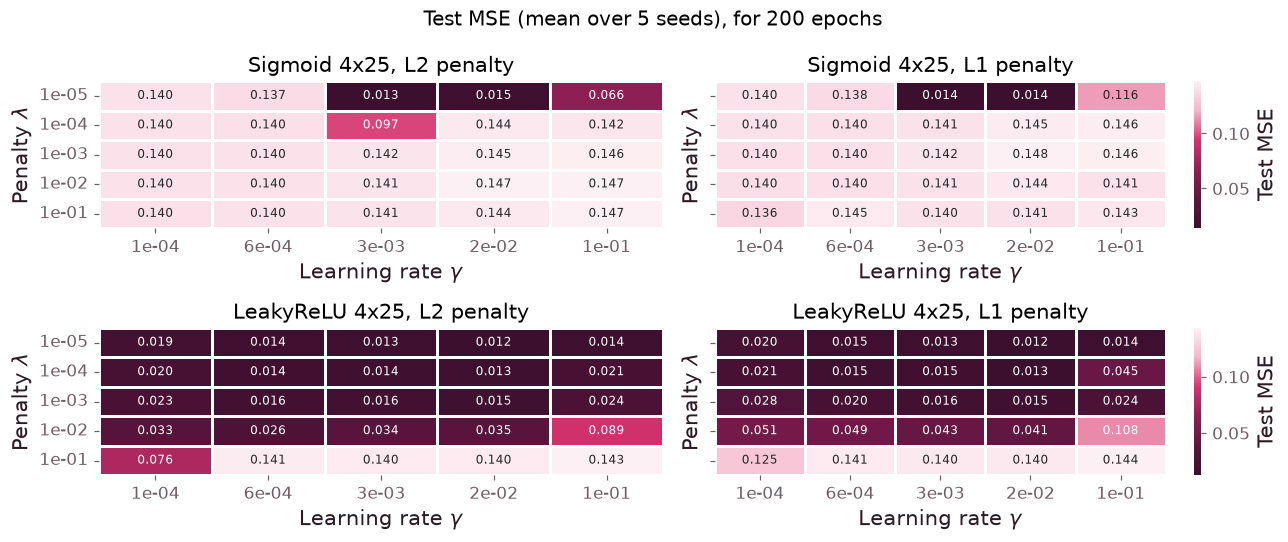

In [3]:
"""Find best hyperparams for for the neural network when adding regularization"""
epochs = 200
batches = 16
seeds = [21, 36, 67, 420, 2026]


best_deg = 11 #from p1 for Ridge and Lasso
lambas = np.logspace(-5, -1, 5)
gammas = np.logspace(-4, -1, 5) #lr


#best nr of nodes and layers for each activation function from c
act_funcs = {'Sigmoid': Sigmoid(), 'LeakyReLU': LeakyReLU()}
sizes = [25, 25, 25, 25, 1]

regs = ('L2', 'L1')

test_mse = np.zeros((len(act_funcs), len(regs), len(lambas), len(gammas), len(seeds)))

for i, (_, act) in enumerate(act_funcs.items()):
    activations = [act] * (len(sizes) - 1) + [Identity()]
    for j, reg in enumerate(regs):
        for k, lamba in enumerate(lambas):
            for l, gamma in enumerate(gammas):
                for m, seed in enumerate(seeds):
                    nn = NeuralNetwork(1, sizes, activations, penalty=Penalty(reg, lamba), seed=seed)
                    train(nn, X_train_s, y_train_s, Adam(gamma), epochs, batches, seed)
                    test_mse[i, j, k, l, m] = MSE()(nn.feed_forward(X_test_s), y_test_s)

test_mean, test_std = test_mse.mean(axis=-1), test_mse.std(axis=-1)

no_pen_mse = np.zeros((len(act_funcs), len(gammas), len(seeds)))


for i, (_, act) in enumerate(act_funcs.items()):
    activations = [act] * (len(sizes) - 1) + [Identity()]
    for l, gamma in enumerate(gammas):
        for m, seed in enumerate(seeds):
            nn = NeuralNetwork(1, sizes, activations, seed=seed)
            train(nn, X_train_s, y_train_s, Adam(gamma), epochs, batches, seed)
            no_pen_mse[i, l, m] = MSE()(nn.feed_forward(X_test_s), y_test_s)

no_pen_mean, no_pen_std = no_pen_mse.mean(axis=-1), no_pen_mse.std(axis=-1)    #shape: (activation, gamma)
l_no_pen = no_pen_mean.argmin(axis=-1)    


"""Ridge and Lasso from project 1, same data and split as the network"""
X_polynom = data.polynomial_features(best_deg, intercept=False)
Xp_train, Xp_test, yp_train, yp_test = data.split(X_polynom)

scaler_poly = Scaler().fit(Xp_train, yp_train)
Xp_train_s, yp_train_s = scaler_poly.transform(Xp_train, yp_train)
Xp_test_s, yp_test_s = scaler_poly.transform(Xp_test, yp_test)

Xp_train_s, Xp_test_s = np.asarray(Xp_train_s), np.asarray(Xp_test_s)
yp_train_s, yp_test_s = np.asarray(yp_train_s).ravel(), np.asarray(yp_test_s).ravel()

ridge_thetas = {lamba: ridge_theta(Xp_train_s, yp_train_s, lamba) for lamba in lambas}
lasso_thetas = {lamba: lasso_theta(Xp_train_s, yp_train_s, lamba, 20000, 1e-8) for lamba in lambas}

ridge = {lamba: float(MSE()(Xp_test_s @ theta, yp_test_s)) for lamba, theta in ridge_thetas.items()}
lasso = {lamba: float(MSE()(Xp_test_s @ theta, yp_test_s)) for lamba, theta in lasso_thetas.items()}


best_ridge = min(ridge, key=ridge.get)
best_lasso = min(lasso, key=lasso.get)

"""Find the best hyperparameters"""
best_hyperparams = {}
for i, act_name in enumerate(act_funcs):
    for j, reg in enumerate(regs):
        k, l = np.unravel_index(np.nanargmin(test_mean[i, j]), test_mean[i, j].shape)
        best_hyperparams[(act_name, reg)] = (lambas[k], gammas[l], test_mean[i, j, k, l], test_std[i, j, k, l])


#Plot heatmaps for the MSEs over lambda and gammas
fig, axes = plt.subplots(len(act_funcs), len(regs), figsize=(12,5), sharey=True)
for i, act_name in enumerate(act_funcs):
    for j, reg in enumerate(regs):
        ax = axes[i, j]
        res = np.where(np.isfinite(test_mean[i, j]), test_mean[i, j], np.nan)
        sea.heatmap(res, ax=ax, cmap=MSE_CMAP, annot=True, fmt='.3f', 
                    annot_kws={'size': 8}, linewidths=1.8, linecolor='white',
                    xticklabels=[f'{g:.0e}' for g in gammas], yticklabels=[f'{lam:.0e}' for lam in lambas],
                    cbar=(j == len(regs) - 1), cbar_kws={'label': 'Test MSE'})
        ax.grid(False)
        ax.set_title(f'{act_name} 4x25, {reg} penalty')
        ax.set_xlabel(r'Learning rate $\gamma$')
        ax.set_ylabel(r'Penalty $\lambda$')
fig.suptitle(f'Test MSE (mean over {len(seeds)} seeds), for {epochs} epochs')
fig.tight_layout()
plt.show()

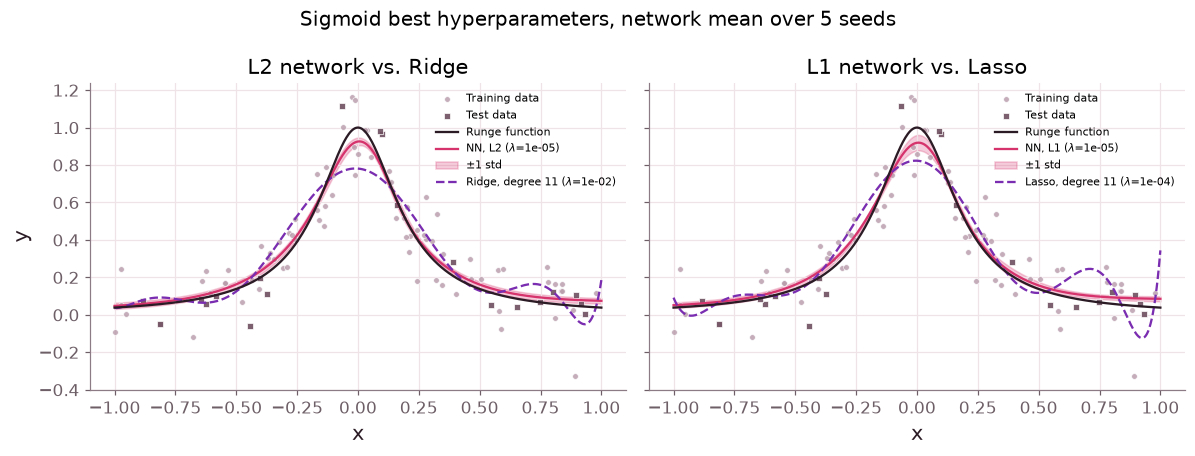

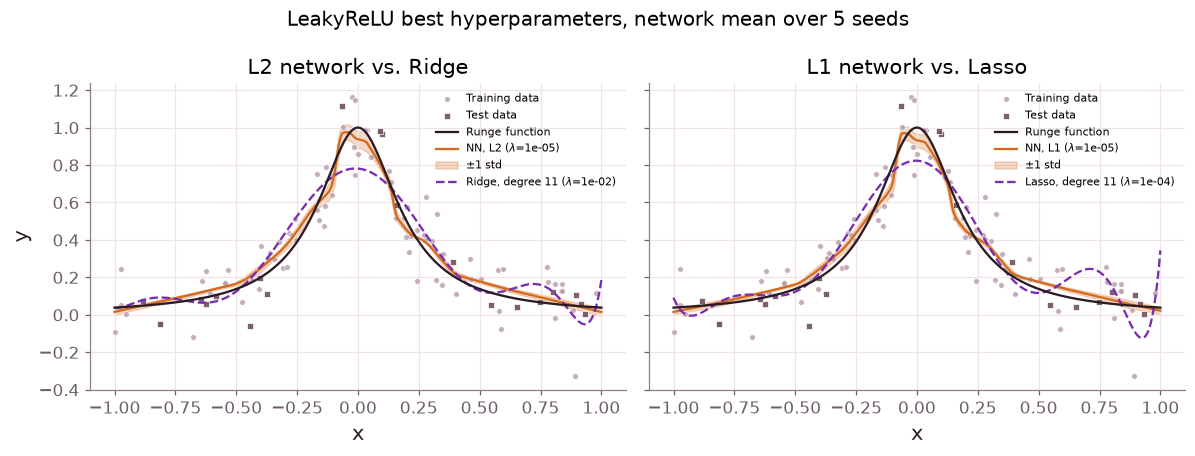

In [4]:
"""The fit using the best hyper parameters"""
x_grid = np.linspace(-1, 1, 400).reshape(-1, 1)
x_grid_s = scaler.transform_X(x_grid)
X_grid_poly_s = np.asarray(scaler_poly.transform_X(RungeData.design_matrix(x_grid.ravel(), best_deg, intercept=False)))

panels = [('L2', 'Ridge', ridge_thetas[best_ridge], best_ridge),
          ('L1', 'Lasso', lasso_thetas[best_lasso], best_lasso)]

for i, (act_name, act) in enumerate(act_funcs.items()):
    activations = [act] * (len(sizes) - 1) + [Identity()]
    color = ACTIVATION_COLORS[act_name]

    fig, axes = plt.subplots(1, len(panels), figsize=(11, 4.2), sharey=True)
    for ax, (reg, name, theta, lam_poly) in zip(axes, panels):
        lam_nn, gam_nn, _, _ = best_hyperparams[(act_name, reg)]

        #one network per seed with the best lambda and gamma, averaged on the grid
        y_grid_all = []
        for seed in seeds:
            nn = NeuralNetwork(1, sizes, activations, penalty=Penalty(reg, lam_nn), seed=seed)
            train(nn, X_train_s, y_train_s, Adam(gam_nn), epochs=epochs, batch_size=batches, seed=seed)
            y_grid_all.append(np.asarray(scaler.inverse_transform_y(nn.feed_forward(x_grid_s))).ravel())
        y_grid_all = np.array(y_grid_all)
        y_mean, y_std = y_grid_all.mean(axis=0), y_grid_all.std(axis=0)

        plot_data_and_truth(ax, x_grid, runge(x_grid), X_train, y_train, X_test, y_test)
        ax.plot(x_grid, y_mean, color=color, label=rf'NN, {reg} ($\lambda$={lam_nn:.0e})')
        ax.fill_between(x_grid.ravel(), y_mean - y_std, y_mean + y_std, color=color, alpha=0.25, label=r'$\pm 1$ std')
        ax.plot(x_grid, scaler_poly.inverse_transform_y(X_grid_poly_s @ theta),
                '--', color=COLORS['ols'], label=rf'{name}, degree {best_deg} ($\lambda$={lam_poly:.0e})')
        ax.set_title(f'{reg} network vs. {name}')
        ax.set_xlabel('x')
        ax.legend(fontsize=7)
    axes[0].set_ylabel('y')
    fig.suptitle(f'{act_name} best hyperparameters, network mean over {len(seeds)} seeds')
    fig.tight_layout()
    plt.show()